# **What the Goodreads Choice Awards Reveal About Reader Preferences and Publishing**
### _Exploring genres, lengths, and what publishers deliver_
Ramisa Zaman

100969638

## 1. Introduction
Goodreads, launched in 2007, is a site that is widely known and used in reading communities. The popular platform allows readers to log and document what they are currently reading, planning to read, and what they have read in the past. Users can also rate and upload reviews for the books they have read, making it one of the go-to sources to find recommendations. In 2009, Goodreads released the Goodreads Choice Awards, where they selected the most popular books of the year and allowed readers to vote for their favourites. As Goodreads has become an industry staple for the book community, I wanted to explore the trends in books over years. Specifically, I want to examine which genres and book lengths have been popular in different years. I also want to investigate how the platform might influence what books publishers release, since it is widely theorized that due to the overwhelming traction Goodreads gets, publishers use its data to try and increase their marketability. I will analyze the Goodreads Choice Awards dataset to uncover patterns in readership and publishing.


## 2. Methods
### 2.1 Data Collection
A dataset of books was found from Kaggle, a public platform where people upload datasets for public use. This dataset contains the books that were the Goodreads Choice Award finalists from 2011-2024 [1].

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ast

In [2]:
#importing raw data
books = pd.read_csv('final_books_data_2011_2024.csv')

### 2.2 Data Cleaning
The book dataset had a few columns that were unnecessary for the analysis, so I removed them. Some of these columns included the book price, author book count, and votes. I also got rid of any rows that contained missing data and the number of reviews since I was only using number of ratings for anaylsis.

In [3]:
#removing columns
books = books.drop(['price', 'num_reviews', 'five_star_percentage', 'five_star_count','four_star_count', 'four_star_percentage', 'three_star_count', 'three_star_percentage', 'two_star_count', 'two_star_percentage', 'one_star_count', 'one_star_percentage','votes', 'author_followers_count', 'author_book_count'], axis = 1)

#get rid of rows with missing data
books = books.dropna(axis=0)

The genres for each book are placed in lists as many of the books cross over multiple genres, so I separated the genres from lists to singular genres.

In [4]:
#first converting any strings to lists and leaving the actual lists alone since I can't separate if all the genres aren't lists
def safe_parse(x):
    if isinstance(x, list):
        return x
    try:
        return ast.literal_eval(x)
    except:
        return []

books['genres'] = books['genres'].apply(safe_parse)

#separating the lists
books_exploded = books.explode('genres')

#removing audiobooks as a type of genre since I am not analysising book format
books_exploded = books_exploded[books_exploded['genres'] != 'Audiobook']

### 2.3 Analysis
I will be investigating the popularity of books over the years based off of their genre and length, and how publishers take this into account.

In [5]:
print(f'The oldest book in the dataset was published in: {books["publication_year"].min()}.\nThe most recent book was published in: {books["publication_year"].max()}')

The oldest book in the dataset was published in: 2000.
The most recent book was published in: 2024


#### Genre and Popularity

I will be exploring the popularity of different genres over the years.

There are a total of 456 different genres found, so in order to visually display the popularity of genres, I chose the top 20 most popular genres to display below.

As you can see, fiction is the overall most popular genre, with many of the top 20 genres being genres that usually fall under the fiction category. However, the secondmost popular category is nonfiction but the gap between it and fiction books is quite large.

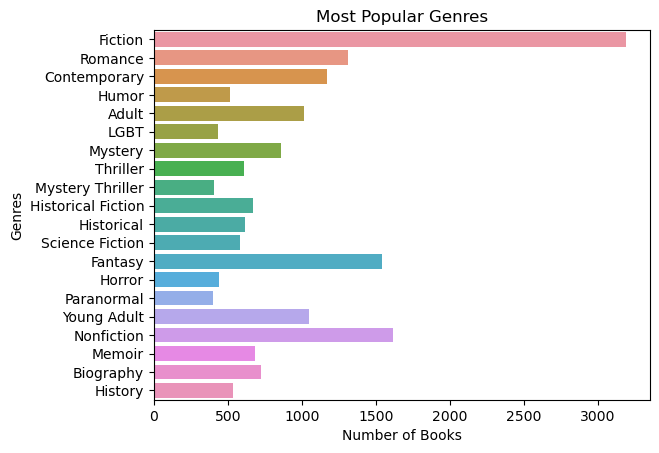

In [6]:
top_genres = books_exploded['genres'].value_counts().nlargest(20).index
f1 = sns.countplot(data = books_exploded[books_exploded['genres'].isin(top_genres)], y='genres')
f1 = f1.set(title = 'Most Popular Genres', xlabel = 'Number of Books', ylabel = 'Genres')

In [7]:
num_fiction = books_exploded[books_exploded.genres=='Fiction'].shape[0]
num_nonfict = books_exploded[books_exploded.genres=='Nonfiction'].shape[0]
difference = (num_fiction - num_nonfict)/num_nonfict*100

print(f"Number of Fiction Books Nominated: {num_fiction}\nNumber of Nonfiction Books Nominated: {num_nonfict}")
print(f"{difference:.2f}% more fiction books were nominated than nonfiction books.")

Number of Fiction Books Nominated: 3191
Number of Nonfiction Books Nominated: 1613
97.83% more fiction books were nominated than nonfiction books.


I examined the Fantasy genre as it is the most popular fiction category. As shown in the data, there was a notable surge of popularity for fantasy books in 2011 to about 2012, followed by a decreased after. Interestly, it seems that fantasy books trend every 4 years, as that is when the amount of nominations increase. However, despite fluctuating, no year has yet to surpassed the level of attention Fantasy garnered in 2011–2012.

In the histogramn to the right, we can observe that publishers appear to attempt to keep up with these trends, by increasing the number of fantasy book releases after each rise in popularity.

This suggests a relationship between the Goodreads Choice Awards and publishing strategies.

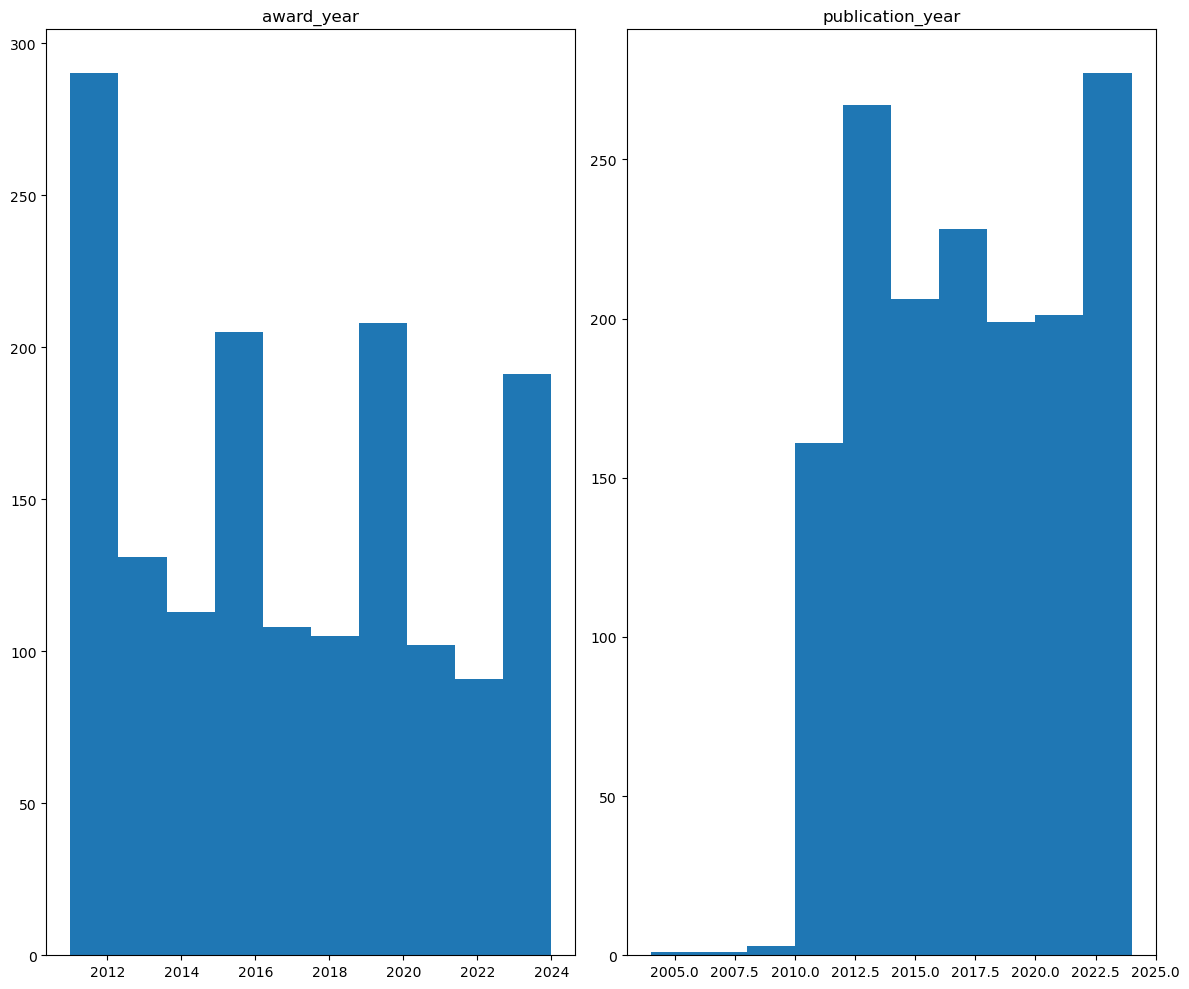

In [8]:
fictBooks = books_exploded[books_exploded.genres=='Fantasy']
f2 = fictBooks[['award_year', 'publication_year']].hist(bins=10, figsize=(12,10), grid =False)
plt.tight_layout()

Now, an examination of genres and the average ratings of their books. This boxplot shows the distribution of average ratings across the top 20 most popular genres. Although history was one of the least popular genres, it is shown to have the highest average ratings. Fantasy and Paranormal also seem have higher medians, while most the rest of the genres seem to cluster around ratings of 3.75 to 4.25.

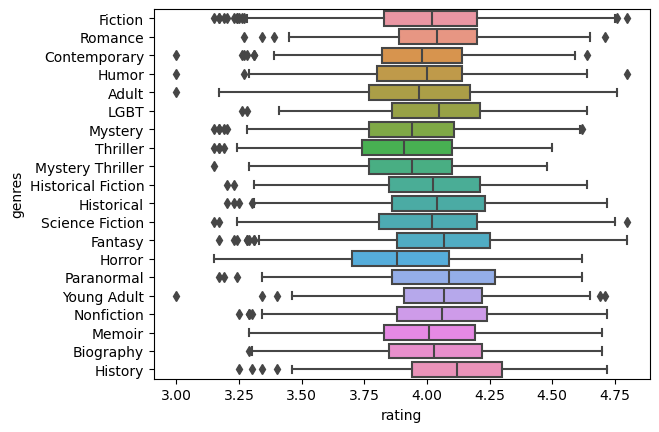

In [9]:
f3 = sns.boxplot(data=books_exploded[books_exploded['genres'].isin(top_genres)], x='rating', y='genres')

#### Page Length and Popularity
A comparison of the number of pages in books and how many times books of that length were nominated was compared to see if there were any patterns there. As you can see below the most popular page lengths are around 300 to 400 pages across all the award years.

In [10]:
#getting the most popular page sizes from each year
year_length = books.groupby(['award_year', 'num_pages']).size()
year_length = year_length.sort_values()
display(year_length.tail(n=30))

award_year  num_pages
2016        336.0        11
2022        304.0        11
2024        304.0        11
2023        288.0        11
2017        304.0        11
2024        320.0        11
2022        368.0        11
2017        320.0        11
2024        400.0        12
2014        368.0        12
2023        432.0        12
2019        336.0        12
2015        352.0        12
2019        288.0        12
2023        384.0        12
2018        256.0        12
2021        256.0        12
2024        336.0        13
2021        336.0        13
2023        352.0        14
2016        352.0        14
2024        368.0        14
2020        304.0        14
2023        416.0        15
            336.0        15
2020        352.0        16
2024        384.0        16
            352.0        18
2023        320.0        22
2015        320.0        22
dtype: int64

The average page length for each year further demonstrates this pattern of books with 300-400 pages being the most popular.

In [11]:
mean_pages = books_exploded.groupby('award_year')['num_pages'].mean()
pd.set_option('display.precision', 2)
display(mean_pages)
print(f"The lowest average page length is {mean_pages.min():.2f}.")
print(f"The highest average page length is {mean_pages.max():.2f}.")
print(f"The overall average is {mean_pages.mean():.2f}.")

award_year
2011    341.34
2012    340.15
2013    348.64
2014    336.23
2015    335.21
2016    332.34
2017    335.28
2018    335.63
2019    333.71
2020    327.76
2021    344.50
2022    345.79
2023    393.75
2024    368.55
Name: num_pages, dtype: float64

The lowest average page length is 327.76.
The highest average page length is 393.75.
The overall average is 344.21.


The plot below further demonstrates the popularity of books 300-400 pages long.

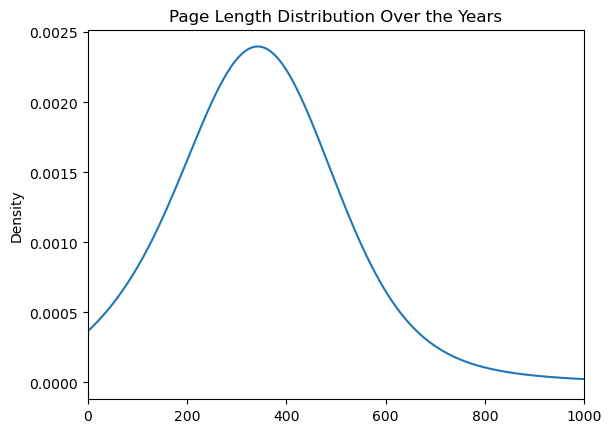

In [ ]:
f4 = books.num_pages.plot.kde(title='Page Length Distribution Over the Years', xlim = (0,1000), bw_method=0.8)

### 3. Discussion

In this assignment, I examined the relationship between book genres, length, and popularity using data from the Goodreads Choice Awards Finalists from 2011–2024, with the goal of understanding how reader preferences evolve over time and how these trends influence the publishing industry. The analysis revealed that fiction consistently overtook the nominations, with fantasy emerging as the most popular genre. Nonfiction, while less nominated than fiction, remained the second most popular category. The outcomes showed that history, a subgenre of nonfiction, had received a higher average rating over fiction genres even though it was less popular. This can indicate that a smaller audience provides a stronger engagement as it is more specialized, so most of the audience are readers that already enjoy the genre.   When examining book length, the data showed a consistent preference for books around 300–400 pages, regardless of genre or year, indicating that readers favor moderately sized works. It was observed that every moment of time where the Fantasy genre was popular, publishers started to release more Fantasy books, suggesting that the publishing industry uses Goodreads to detect reader patterns and align their own books with theirs. In conclusion, platforms like Goodreads provide publishers with insights to help them respond to emerging trends in popular genres and help them plan out their book releases to meet the everchanging reader expectations.

### 4. GenAi Disclosure - ChatGPT
1. Used it to help separate the genres from lists into separate individual genres.  
  Prompt: "lets say i have book genres in a list, how would i separate it to access each individual element from the genres with seaborn"  
  Answer: "You need to explode the list so each genre becomes its own row."
  It didn't work after this as it still saved the genres as their entire lists. I noticed some of values were strings.
  Prompt: "Fix it if they are strings pretending to be lists. Convert the string to an actual list using ast.literal_eval:"
  But ast.literal_eval only works when all the values of genres are strings that are made to look like lists, but I had some actual list values.  
  Answer: "Safely convert only valid rows & ignore bad ones. Use a helper function that tries to parse, and if parsing fails, returns the value as-is:"  
  I then went and used a try except and made sure it if the parsing fails, it returns an empty list instead of None.

2. Used it to help get the find the most popular genres in the dataset.   
  Prompt: "How would I get the genres with the most books in it"  
  Answer: "Get only the top N most common genres using .nlargest()"


### 5. References
1. Source data - https://www.kaggle.com/datasets/krisbruurs/goodreads-choice-awards-2011-2024-books/data
2. Pandas for data manipulation
3. Seaborn for data viz
4. Matplotlib for data viz 
5. Ast for safely parsing strings into lists - https://docs.python.org/3/library/ast.html